# Analiza i Predykcja Churnu Użytkowników Platformy Streamingowej

## 1. Wstęp i Kontekst Biznesowy
Pozyskanie nowego klienta w branży usług subskrypcyjnych jest od kilkukrotnie do kilkunastokrotnie droższe niż utrzymanie obecnego użytkownika. Zjawisko rezygnacji z usług (tzw. **Churn**) bezpośrednio wpływa na spadek przychodów firmy oraz rentowność całej platformy. Identyfikacja klientów zagrożonych odejściem pozwala na wcześniejszą reakcję i podjęcie działań retencyjnych.

## 2. Cel Analizy
Głównym celem projektu jest:
1. **Analiza eksploracyjna (EDA):** Zidentyfikowanie kluczowych czynników wpływających na decyzję użytkownika o rezygnacji z subskrypcji.
2. **Modelowanie ML:** Zbudowanie oraz optymalizacja modelu uczenia maszynowego (klasyfikatora), który z wysoką precyzją przewidzi, czy dany klient opuści platformę.

## 3. Interesariusz (Stakeholder)
Odbiorcą wyników analizy jest **Dział Retencji i Marketingu platformy streamingowej**. Wyniki modelu posłużą do automatycznego targetowania spersonalizowanych ofert promocyjnych (np. zniżki, dedykowane pakiety) do osób o wysokim ryzyku odejścia.

## 4. Opis Zbioru Danych
Zbiór zawiera dane demonstracyjne klientów sieci/usług subskrypcyjnych (`Telco Customer Churn`). Obejmuje informacje o:
* Demografii (płeć, seniorzy, partnerzy),
* Usługach (zestaw wykupionych pakietów, ochrona urządzeń, streaming wideo),
* Umowie i płatnościach (typ umowy, metoda płatności, koszty miesięczne i całkowite),
* Zmiennej docelowej: `Churn` (Tak/Nie).

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ustawienia graficzne wykresów
sns.set_theme(style="whitegrid")

# Wczytanie pliku CSV z danymi
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Wyświetlenie rozmiaru zbioru oraz pierwszych 5 wierszy
print(f"Liczba wierszy (klientów): {df.shape[0]}")
print(f"Liczba kolumn (cech): {df.shape[1]}\n")

df.head()

Liczba wierszy (klientów): 7043
Liczba kolumn (cech): 21



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
# Sprawdzamy typy kolumn oraz czy występują ukryte braki danych
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Markdown
## 5. Czyszczenie i przygotowanie danych (Data Cleaning)

In [24]:
# 1. Konwersja TotalCharges na typ numeryczny (spacje zmienią się na NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 2. Usunięcie wierszy z brakami wartości (dotyczy 11 nowych klientów z tenure=0)
df.dropna(inplace=True)

# 3. Usunięcie kolumny customerID (nie wnosi wartości do modelu ML)
df.drop(columns=['customerID'], inplace=True)

# 4. Konwersja zmiennej docelowej Churn z 'Yes'/'No' na 1/0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Potwierdzenie poprawnej konwersji
print(f"Pozostała liczba wierszy po wyczyszczeniu: {len(df)}")
print(f"Brakujące wartości w zbiorze: {df.isnull().sum().sum()}")
df.head(3)

Pozostała liczba wierszy po wyczyszczeniu: 7032
Brakujące wartości w zbiorze: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


## 6. Analiza Eksploracyjna Danych (EDA)
Analiza rozkładu zmiennej docelowej oraz wpływu typu umowy na rezygnację klientów.

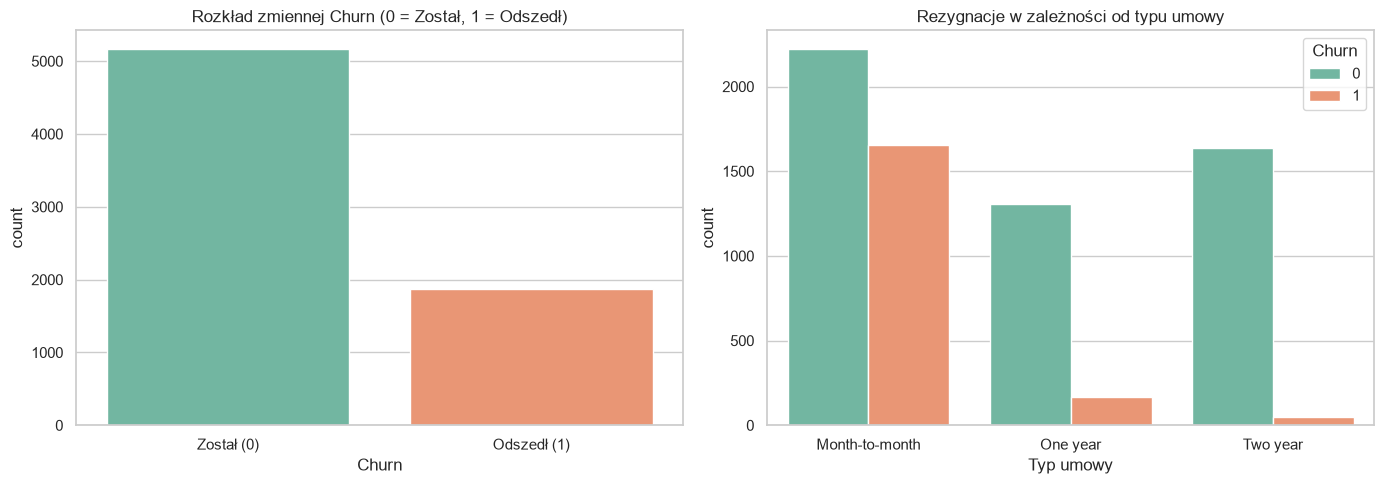

In [25]:
import warnings
warnings.filterwarnings('ignore')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Wykres 1: Rozkład rezygnacji (Churn)
sns.countplot(x='Churn', hue='Churn', data=df, ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Rozkład zmiennej Churn (0 = Został, 1 = Odszedł)')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Został (0)', 'Odszedł (1)'])

# Wykres 2: Churn a typ umowy (Contract)
sns.countplot(x='Contract', hue='Churn', data=df, ax=axes[1], palette='Set2')
axes[1].set_title('Rezygnacje w zależności od typu umowy')
axes[1].set_xlabel('Typ umowy')

plt.tight_layout()
plt.show()

### Wnioski z analizy eksploracyjnej:
1. **Niezbalansowana klasa:** Większość klientów zostaje w usłudze, odchodzi około 26.5% użytkowników.
2. **Wpływ typu umowy:** Klienci posiadający umowę miesiąc-do-miesiąca (`Month-to-month`) odchodzą znacznie częściej niż osoby z umowami długoterminowymi (1-rok lub 2-lata).

## 7. Kodowanie zmiennych i podział na zbiór treningowy/testowy
Model ML wymaga wartości numerycznych. Zamieniamy zmienne tekstowe (kategoryczne) na liczby za pomocą One-Hot Encoding (`pd.get_dummies`).


In [26]:
# Separate predictors (X) and target (y)
X = df.drop(columns=['Churn'])
y = df['Churn']

# One-Hot Encoding dla zmiennych kategorycznych
X_encoded = pd.get_dummies(X, drop_first=True)

print(f"Liczba cech po kodowaniu One-Hot Encoding: {X_encoded.shape[1]}")
X_encoded.head(3)

Liczba cech po kodowaniu One-Hot Encoding: 30


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True


## 8. Podział danych i trening modelu bazowego
W tym kroku:
1. Dzielimy dane na zbiór treningowy (80%) oraz testowy (20%) z zachowaniem proporcji klas (`stratify=y`).
2. Trenujemy bazowy model **Random Forest Classifier** (Las Losowy).
3. Evaluujemy model na danych testowych za pomocą wskaźników: Accuracy, Precision, Recall oraz F1-Score.

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Podział na zbiór treningowy (80%) i testowy (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Inicjalizacja i trening modelu bazowego
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

# Predykcja na zbiorze testowym
y_pred = rf_model.predict(X_test)

# Ocena wyników
print(f"Dokładność (Accuracy): {accuracy_score(y_test, y_pred):.4f}\n")
print("Raport klasyfikacji:")
print(classification_report(y_test, y_pred))

Dokładność (Accuracy): 0.7896

Raport klasyfikacji:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



## 9. Optymalizacja hiperparametrów (GridSearchCV)
Model bazowy słabo radził sobie z wykrywaniem klientów odchodzących (Recall = 0.52). 
Optymalizujemy parametry Lasu Losowego za pomocą `GridSearchCV`, uwzględniając balansowanie wag klas (`class_weight='balanced'`).

In [28]:
from sklearn.model_selection import GridSearchCV

# Definicja siatki hiperparametrów
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15],
    'class_weight': ['balanced', 'balanced_subsample']
}

# Szukanie najlepszej kombinacji
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Najlepszy model
best_rf = grid_search.best_estimator_
y_pred_opt = best_rf.predict(X_test)

print("Najlepsze parametry:", grid_search.best_params_)

Najlepsze parametry: {'class_weight': 'balanced', 'max_depth': 5, 'n_estimators': 100}


## 10. Porównanie z modelem XGBoost
Wdrażamy algorytm **XGBoost Classifier** i porównujemy wszystkie podejścia w zbiorczej tabeli.

In [29]:
from xgboost import XGBClassifier
from sklearn.metrics import recall_score, precision_score

# 1. Trening XGBoost z równoważeniem klas
ratio = (len(y_train) - sum(y_train)) / sum(y_train)
xgb_model = XGBClassifier(scale_pos_weight=ratio, random_state=42, eval_metric='logloss')
xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

# 2. Tabela podsumowująca
results = pd.DataFrame({
    'Model': ['Random Forest (Bazowy)', 'Random Forest (GridSearch)', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_opt),
        accuracy_score(y_test, y_pred_xgb)
    ],
    'Recall (Odchodzący)': [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_opt),
        recall_score(y_test, y_pred_xgb)
    ],
    'Precision (Odchodzący)': [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_opt),
        precision_score(y_test, y_pred_xgb)
    ]
})

results


,Model,Accuracy,Recall (Odchodzący),Precision (Odchodzący)
0,Random Forest (Bazowy),0.789623,0.518717,0.625806
1,Random Forest (GridSearch),0.723525,0.823529,0.488114
2,XGBoost,0.742004,0.660428,0.511387


## 11. Podsumowanie i Rekomendacje Biznesowe (Stakeholder)

### Wnioski z modelowania:
1. **Wybór optymalnego modelu:** Z punktu widzenia biznesu kluczowym wskaźnikiem jest **Recall** (wykrywalność klientów faktycznie zagrożonych rezygnacją). Model **Random Forest poddany optymalizacji (GridSearchCV)** osiągnął najwyższy Recall (**82.35%**), skutecznie wyłapując zdecydowaną większość odchodzących użytkowników.
2. **Trade-off (Kompromis):** Zwiększenie wykrywalności wiązało się ze spadkiem ogólnej dokładności (Accuracy do 72.35%), co oznacza pewną liczbę fałszywych alarmów. W kontekście utrzymania klienta koszt wysłania promocji do kogoś, kto i tak by został, jest znacznie niższy niż strata odchodzącego klienta.

### Rekomendacje dla Działu Retencji i Marketingu:
1. **Targetowanie umów krótkoterminowych:** Klienci korzystający z umów miesiąc-do-miesiąca (`Month-to-month`) stanowią grupę najwyższego ryzyka. Zaleca się przygotowanie dedykowanych promocji zachęcających do przejścia na umowy roczne.
2. **Automatyczny system wczesnego ostrzegania:** Wdrożenie modelu `Random Forest (GridSearch)` do systemu CRM w celu automatycznego flagowania użytkowników o ryzyku rezygnacji > 80% i kierowania do nich spersonalizowanych rabatów lub darmowych dodatków przed wygaśnięciem okresu rozliczeniowego.